In [40]:

# Simulate real-time filtering in 1-second blocks

block_size = 250

# Initialize with zero states
zi = np.zeros((heart_sos.shape[0], 2))

streaming_output = []

for start in range(0, len(x), block_size):

    block = x[start:start + block_size]

    filtered_block, zi = signal.sosfilt(
        heart_sos,
        block,
        zi=zi
    )

    streaming_output.extend(filtered_block)

streaming_output = np.asarray(streaming_output)

# Compare against continuous causal filtering
difference = np.max(
    np.abs(streaming_output - heart_causal)
)

print("Streaming simulation completed.")
print(f"Maximum difference: {difference:.12e}")



Streaming simulation completed.
Maximum difference: 0.000000000000e+00


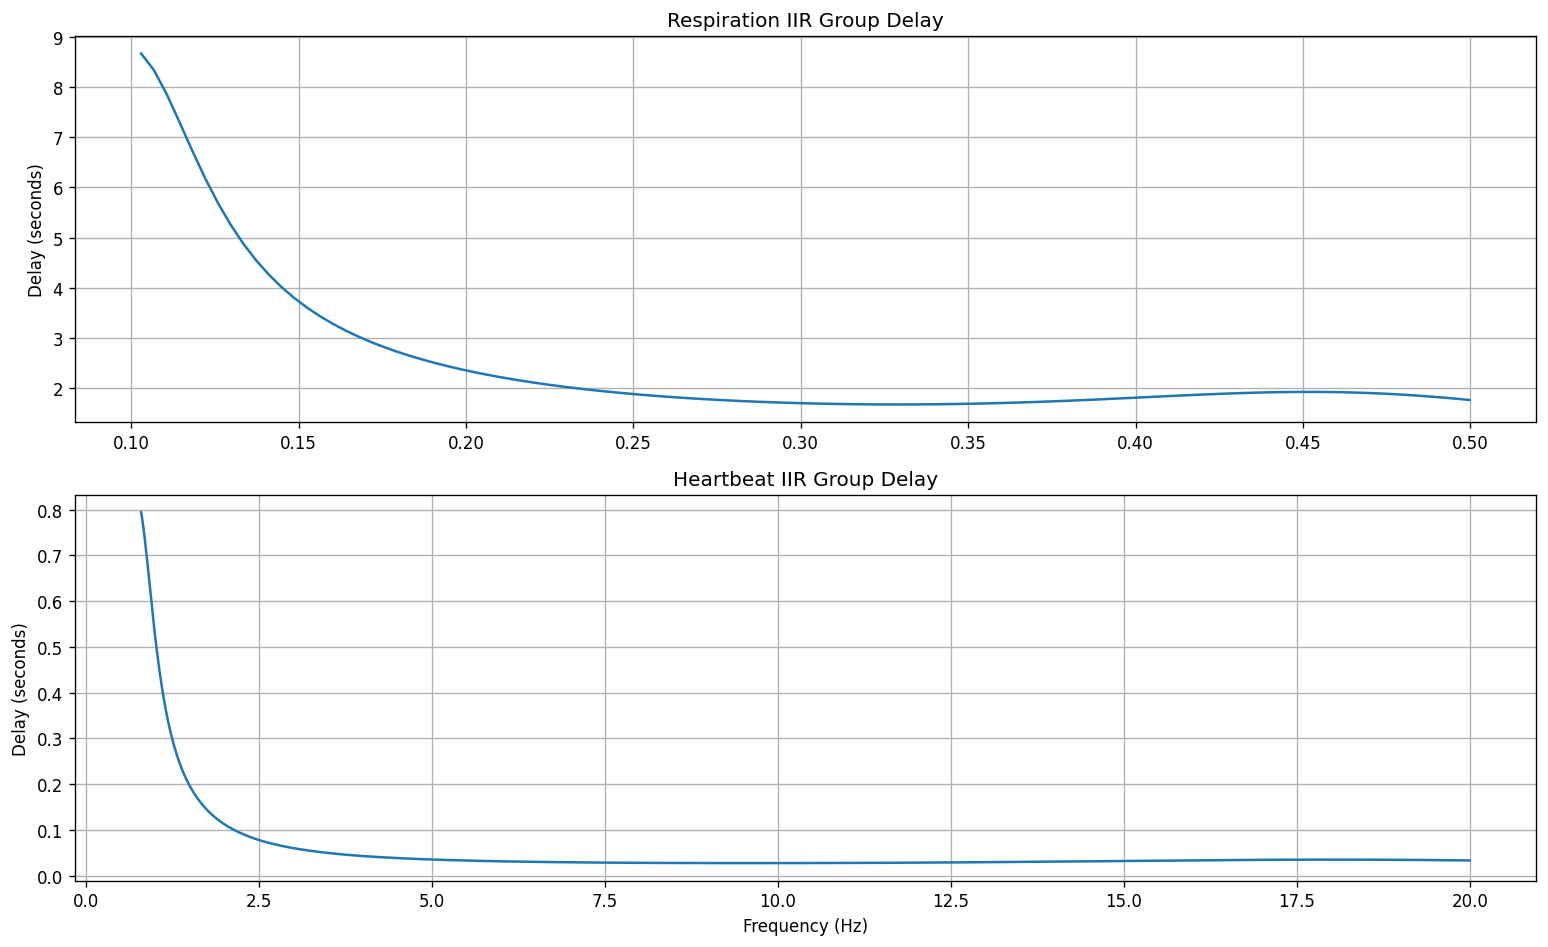

In [38]:

def calculate_group_delay(sos, fs):

    freq, response = signal.sosfreqz(
        sos,
        worN=32768,
        fs=fs
    )

    phase = np.unwrap(np.angle(response))

    omega = 2 * np.pi * freq / fs

    gd = -np.gradient(phase, omega)

    return freq, gd


freq_resp, gd_resp = calculate_group_delay(resp_sos, fs)
freq_heart, gd_heart = calculate_group_delay(heart_sos, fs)

fig, axes = plt.subplots(2, 1, figsize=(13, 8))

mask_resp = (freq_resp >= 0.1) & (freq_resp <= 0.5)
mask_heart = (freq_heart >= 0.8) & (freq_heart <= 20)

axes[0].plot(freq_resp[mask_resp], gd_resp[mask_resp] / fs)
axes[0].set_title("Respiration IIR Group Delay")
axes[0].set_ylabel("Delay (seconds)")

axes[1].plot(freq_heart[mask_heart], gd_heart[mask_heart] / fs)
axes[1].set_title("Heartbeat IIR Group Delay")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Delay (seconds)")

plt.tight_layout()
plt.savefig("../figures/21_iir_group_delay.png")
plt.show()


In [37]:

def estimate_delay(causal, zero_phase, fs, trim_seconds=3):

    # Remove beginning and ending transients
    trim = int(trim_seconds * fs)

    a = causal[trim:-trim]
    b = zero_phase[trim:-trim]

    # Remove DC components
    a = a - np.mean(a)
    b = b - np.mean(b)

    correlation = signal.correlate(
        a, b, mode="full", method="fft"
    )

    lags = signal.correlation_lags(
        len(a), len(b), mode="full"
    )

    best_lag = lags[np.argmax(correlation)]

    delay_seconds = best_lag / fs

    return best_lag, delay_seconds


resp_lag, resp_delay = estimate_delay(
    resp_causal, resp_zero_phase, fs
)

heart_lag, heart_delay = estimate_delay(
    heart_causal, heart_zero_phase, fs
)

print("CAUSAL FILTER DELAY")
print("---------------------------")

print(f"Respiration lag: {resp_lag} samples")
print(f"Respiration delay: {resp_delay:.4f} seconds")

print(f"\nHeartbeat lag: {heart_lag} samples")
print(f"Heartbeat delay: {heart_delay:.4f} seconds")


CAUSAL FILTER DELAY
---------------------------
Respiration lag: 41 samples
Respiration delay: 0.1640 seconds

Heartbeat lag: -58 samples
Heartbeat delay: -0.2320 seconds


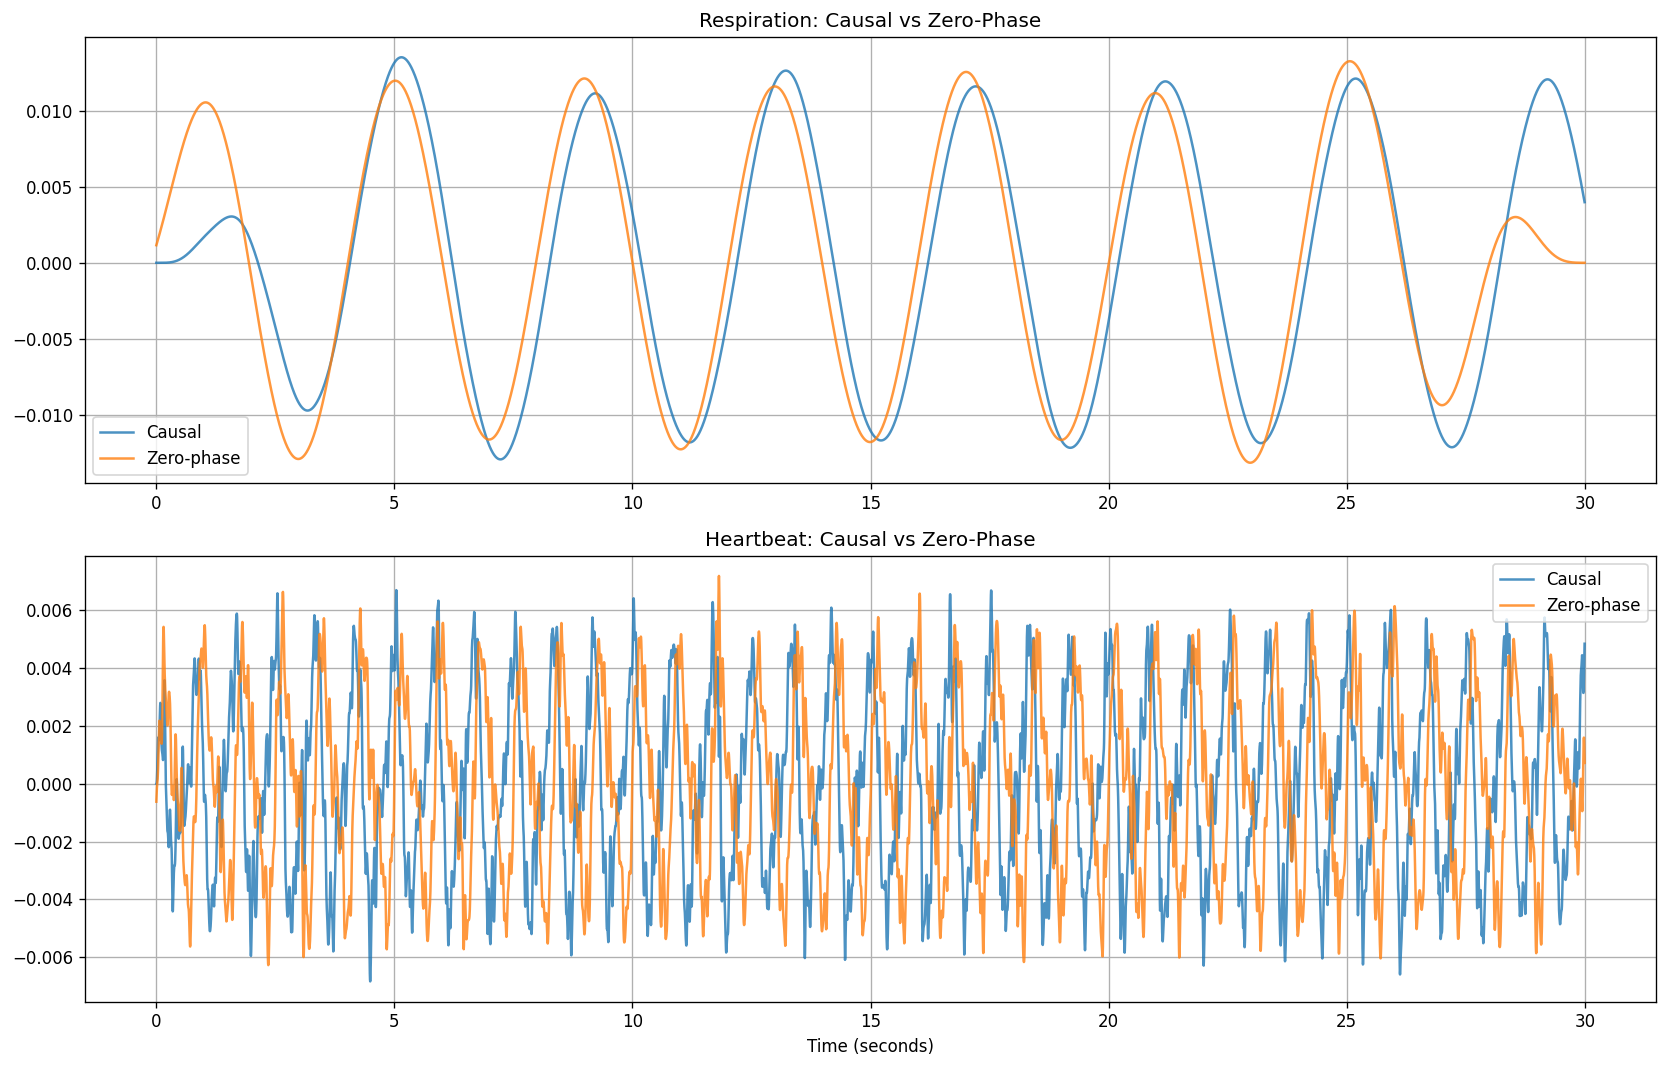

In [36]:

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

# Respiration
axes[0].plot(
    time, resp_causal,
    label="Causal",
    alpha=0.8
)

axes[0].plot(
    time, resp_zero_phase,
    label="Zero-phase",
    alpha=0.8
)

axes[0].set_title("Respiration: Causal vs Zero-Phase")
axes[0].legend()

# Heartbeat
axes[1].plot(
    time, heart_causal,
    label="Causal",
    alpha=0.8
)

axes[1].plot(
    time, heart_zero_phase,
    label="Zero-phase",
    alpha=0.8
)

axes[1].set_title("Heartbeat: Causal vs Zero-Phase")
axes[1].set_xlabel("Time (seconds)")
axes[1].legend()

plt.tight_layout()
plt.savefig("../figures/20_causal_zero_phase_overlay.png")
plt.show()


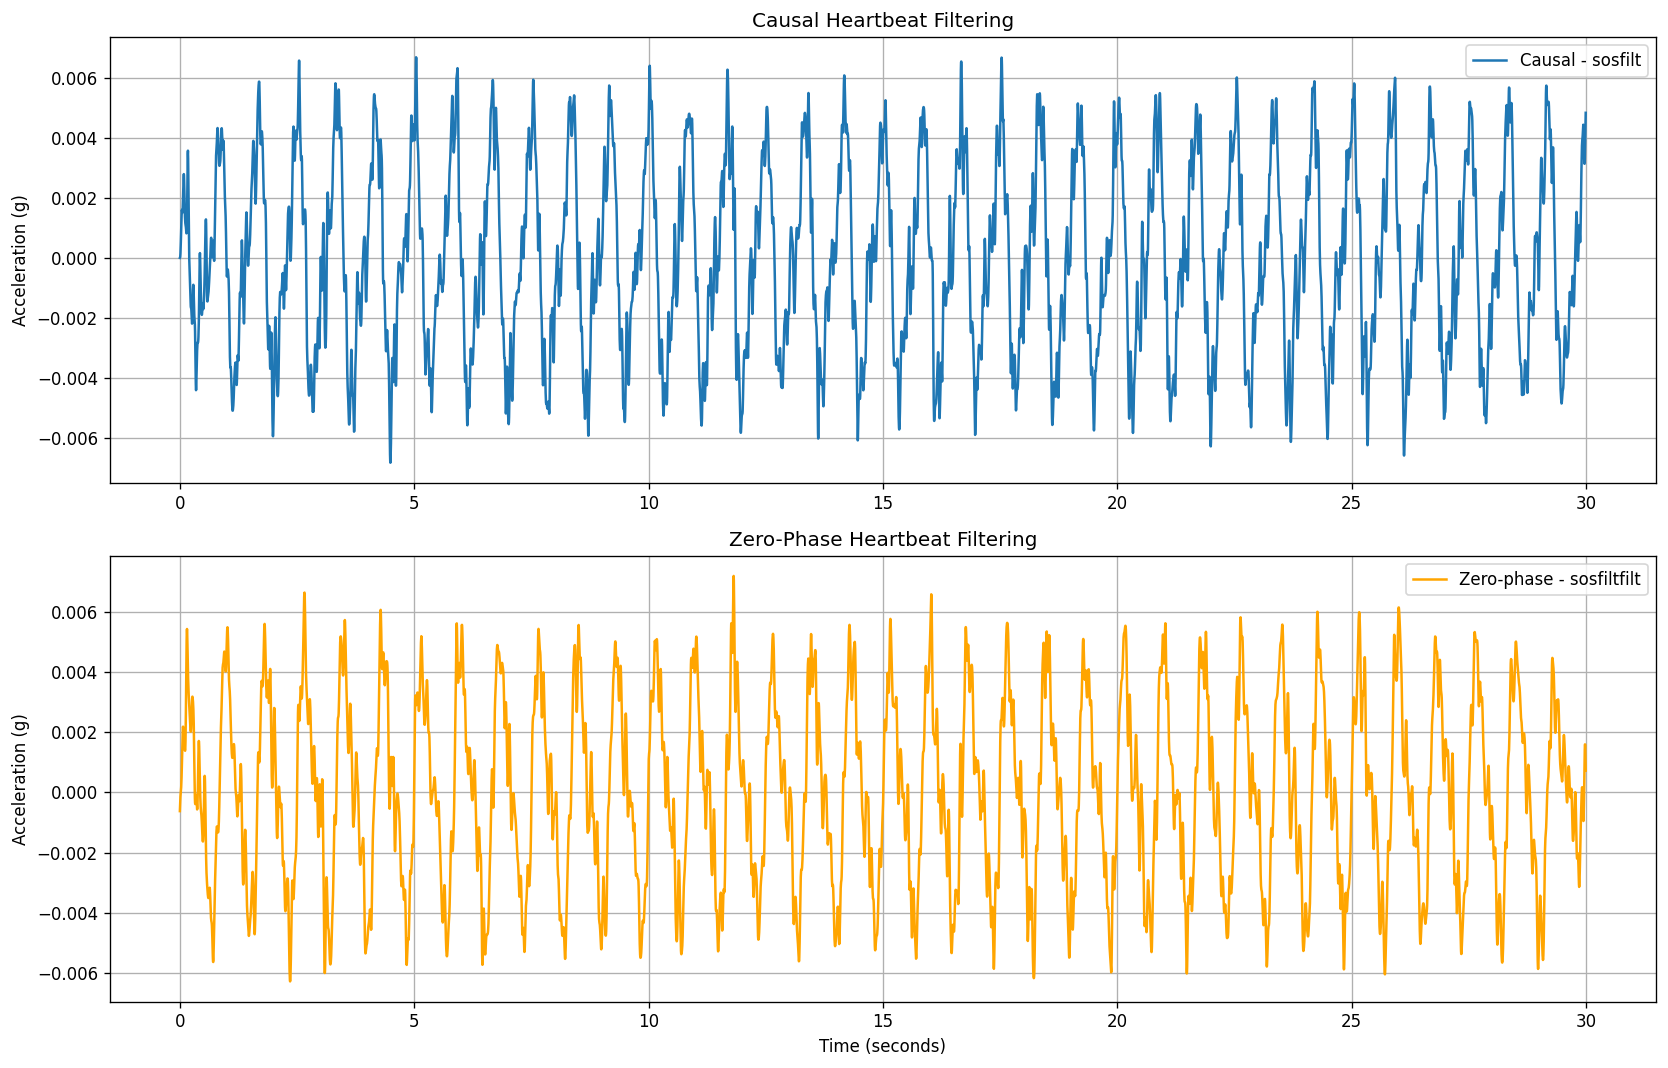

In [35]:

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

axes[0].plot(
    time, heart_causal,
    label="Causal - sosfilt"
)

axes[0].set_title("Causal Heartbeat Filtering")
axes[0].set_ylabel("Acceleration (g)")
axes[0].legend()

axes[1].plot(
    time, heart_zero_phase,
    label="Zero-phase - sosfiltfilt",
    color="orange"
)

axes[1].set_title("Zero-Phase Heartbeat Filtering")
axes[1].set_ylabel("Acceleration (g)")
axes[1].set_xlabel("Time (seconds)")
axes[1].legend()

plt.tight_layout()
plt.savefig("../figures/19_causal_vs_zero_phase_hr.png")
plt.show()


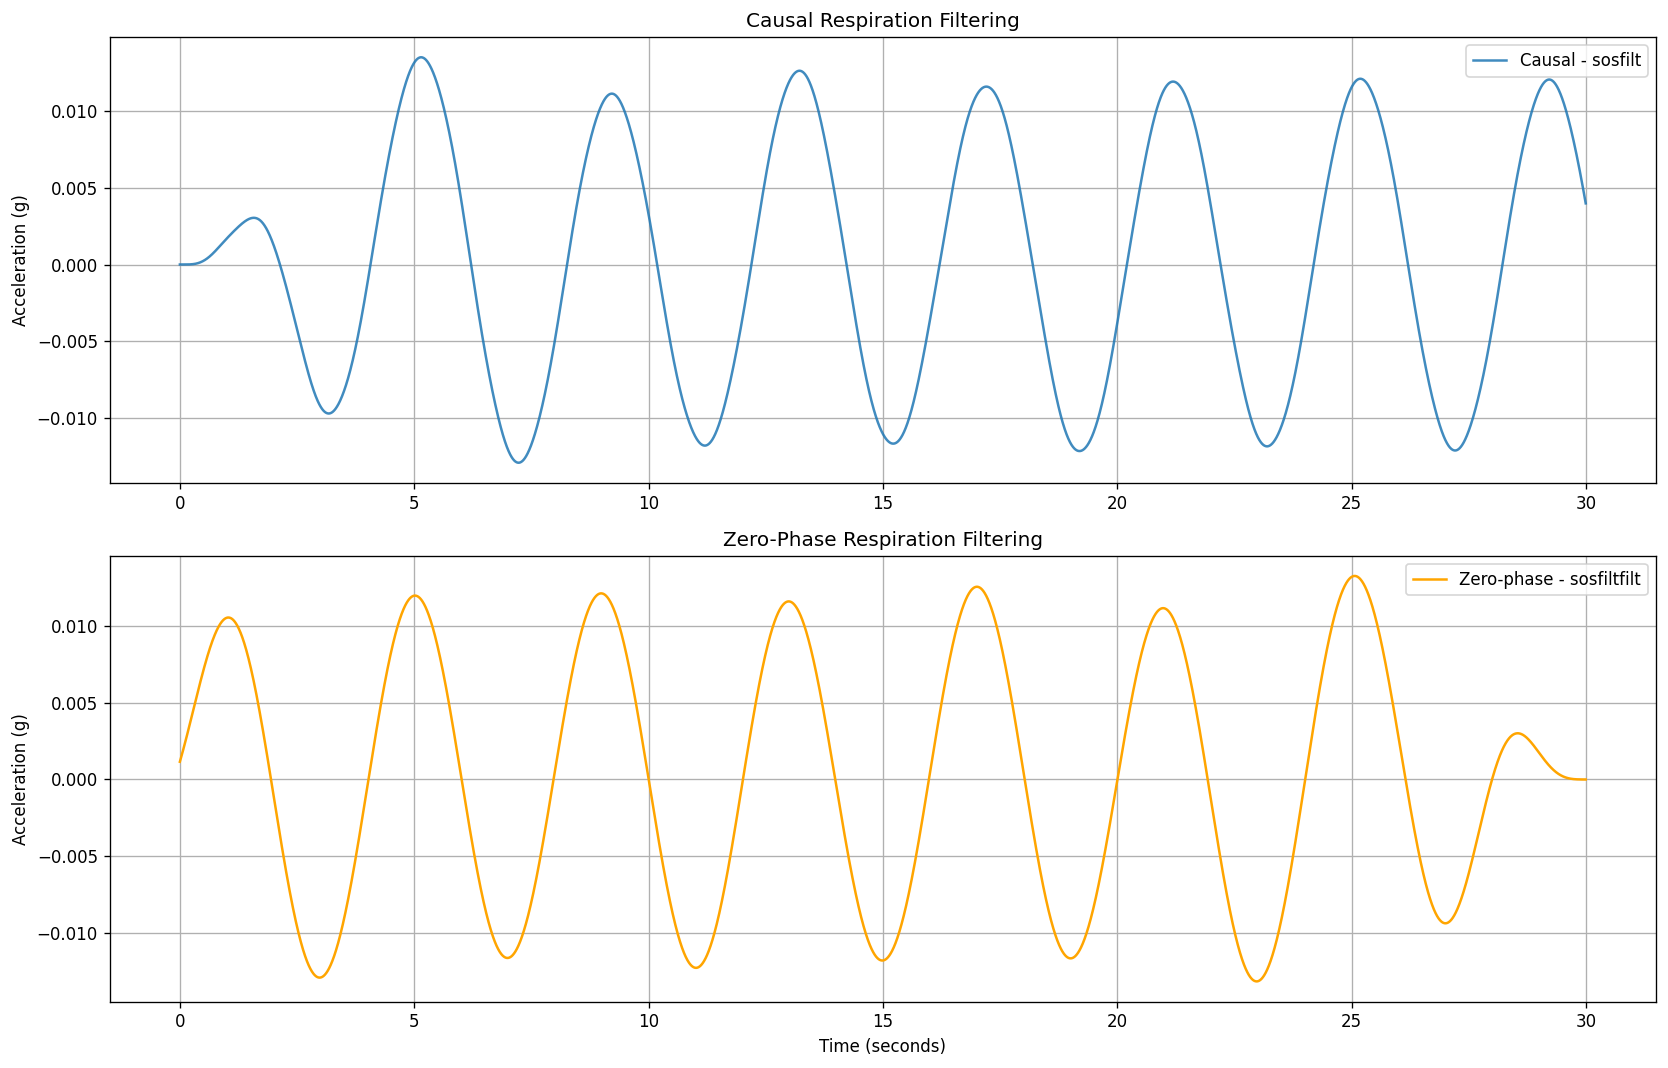

In [34]:

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

axes[0].plot(
    time, resp_causal,
    label="Causal - sosfilt",
    alpha=0.85
)

axes[0].set_title("Causal Respiration Filtering")
axes[0].set_ylabel("Acceleration (g)")
axes[0].legend()

axes[1].plot(
    time, resp_zero_phase,
    label="Zero-phase - sosfiltfilt",
    color="orange"
)

axes[1].set_title("Zero-Phase Respiration Filtering")
axes[1].set_ylabel("Acceleration (g)")
axes[1].set_xlabel("Time (seconds)")
axes[1].legend()

plt.tight_layout()
plt.savefig("../figures/18_causal_vs_zero_phase_resp.png")
plt.show()


In [33]:

# Zero-phase filtering

heart_zero_phase = signal.sosfiltfilt(
    heart_sos, x
)

resp_zero_phase = signal.sosfiltfilt(
    resp_sos, x
)

print("Zero-phase filtering completed.")


Zero-phase filtering completed.


In [32]:

# Causal filtering

heart_causal = signal.sosfilt(heart_sos, x)

resp_causal = signal.sosfilt(resp_sos, x)

print("Causal filtering completed.")


Causal filtering completed.


In [31]:

# Causal vs zero-phase filter comparison

# Heartbeat band-pass filter
heart_sos = signal.butter(
    N=4,
    Wn=[0.8, 20],
    btype="bandpass",
    fs=fs,
    output="sos"
)

# Respiration band-pass filter
resp_sos = signal.butter(
    N=4,
    Wn=[0.1, 0.5],
    btype="bandpass",
    fs=fs,
    output="sos"
)

print("Heartbeat and respiration filters ready.")


Heartbeat and respiration filters ready.


In [30]:

stability_df.to_csv(
    "../data/processed/filter_stability.csv",
    index=False
)

performance_df.to_csv(
    "../data/processed/filter_performance.csv",
    index=False
)

print("Filter analysis tables saved successfully!")


Filter analysis tables saved successfully!


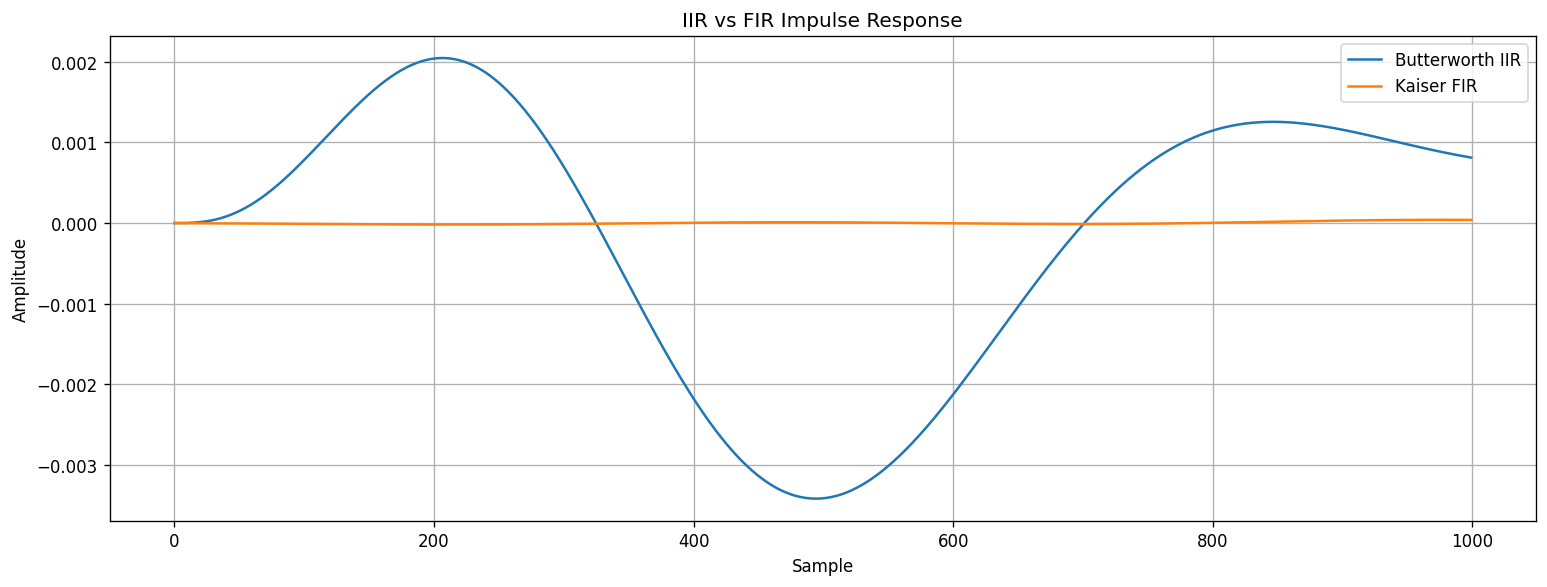

In [29]:

N = 1000

impulse = np.zeros(N)
impulse[0] = 1

# IIR Butterworth
iir_impulse = signal.sosfilt(resp_sos, impulse)

# FIR Kaiser
fir_impulse = resp_fir_kaiser[:N]

plt.figure(figsize=(13, 5))

plt.plot(iir_impulse, label="Butterworth IIR")
plt.plot(fir_impulse, label="Kaiser FIR")

plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.title("IIR vs FIR Impulse Response")

plt.legend()
plt.tight_layout()

plt.savefig("../figures/17_iir_fir_impulse.png")
plt.show()


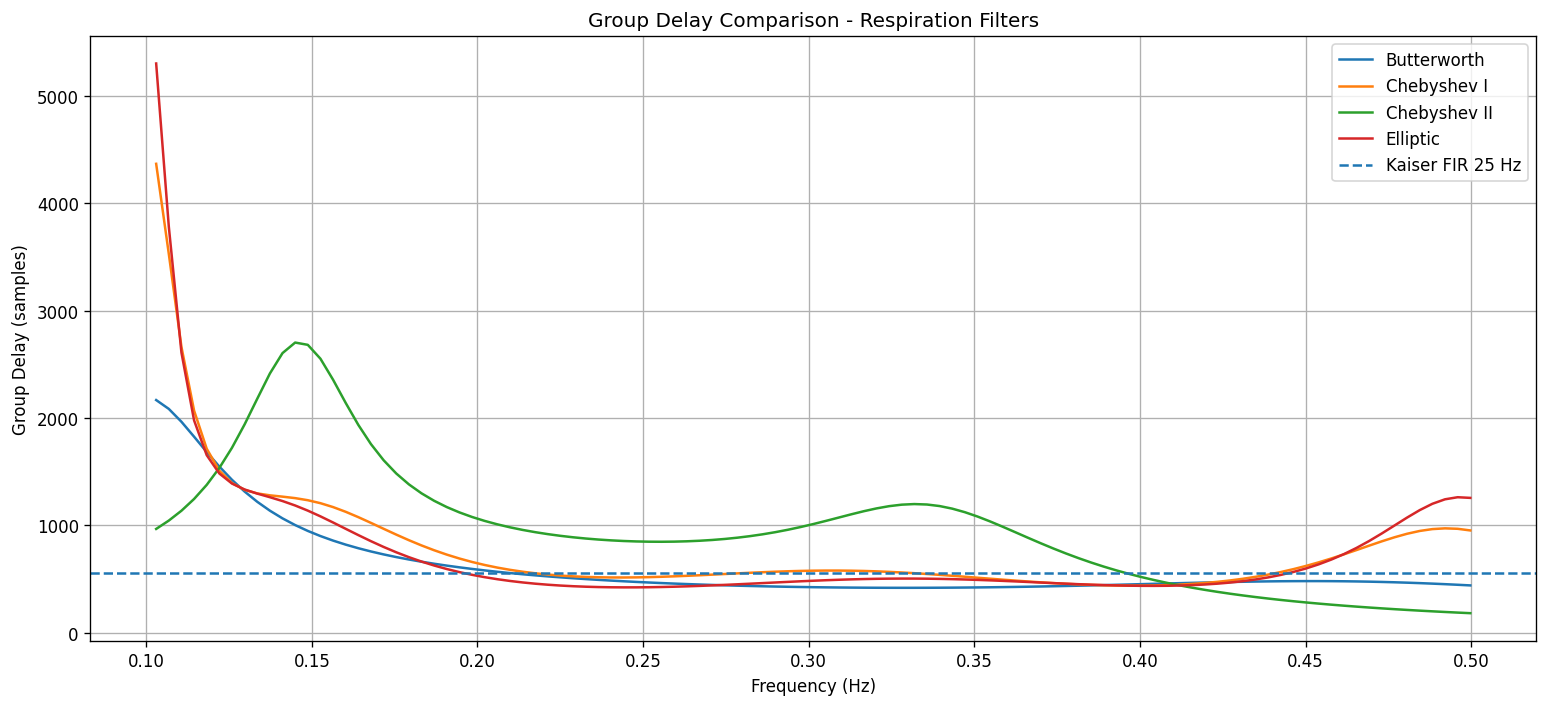

Kaiser FIR group delay:
559 samples at 25.00 Hz
22.360 seconds


In [28]:

# Group delay comparison

fig, ax = plt.subplots(figsize=(13, 6))

for name, sos in iir_filters.items():

    freq, response = signal.sosfreqz(
        sos,
        worN=32768,
        fs=fs
    )

    phase = np.unwrap(np.angle(response))

    # Convert frequency in Hz to angular frequency in rad/sample
    omega = 2 * np.pi * freq / fs

    group_delay = -np.gradient(phase, omega)

    # Display only respiration passband
    mask = (freq >= 0.1) & (freq <= 0.5)

    ax.plot(
        freq[mask],
        group_delay[mask],
        label=name
    )

# FIR group delay is constant for symmetric FIR filters
fir_delay = (len(resp_fir_25) - 1) / 2

ax.axhline(
    fir_delay,
    linestyle="--",
    label="Kaiser FIR 25 Hz"
)

ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Group Delay (samples)")
ax.set_title("Group Delay Comparison - Respiration Filters")

ax.legend()
ax.grid(True)

plt.tight_layout()
plt.savefig("../figures/16_group_delay_comparison.png")
plt.show()

print("Kaiser FIR group delay:")
print(f"{fir_delay:.0f} samples at {fs_decimated:.2f} Hz")
print(f"{fir_delay/fs_decimated:.3f} seconds")


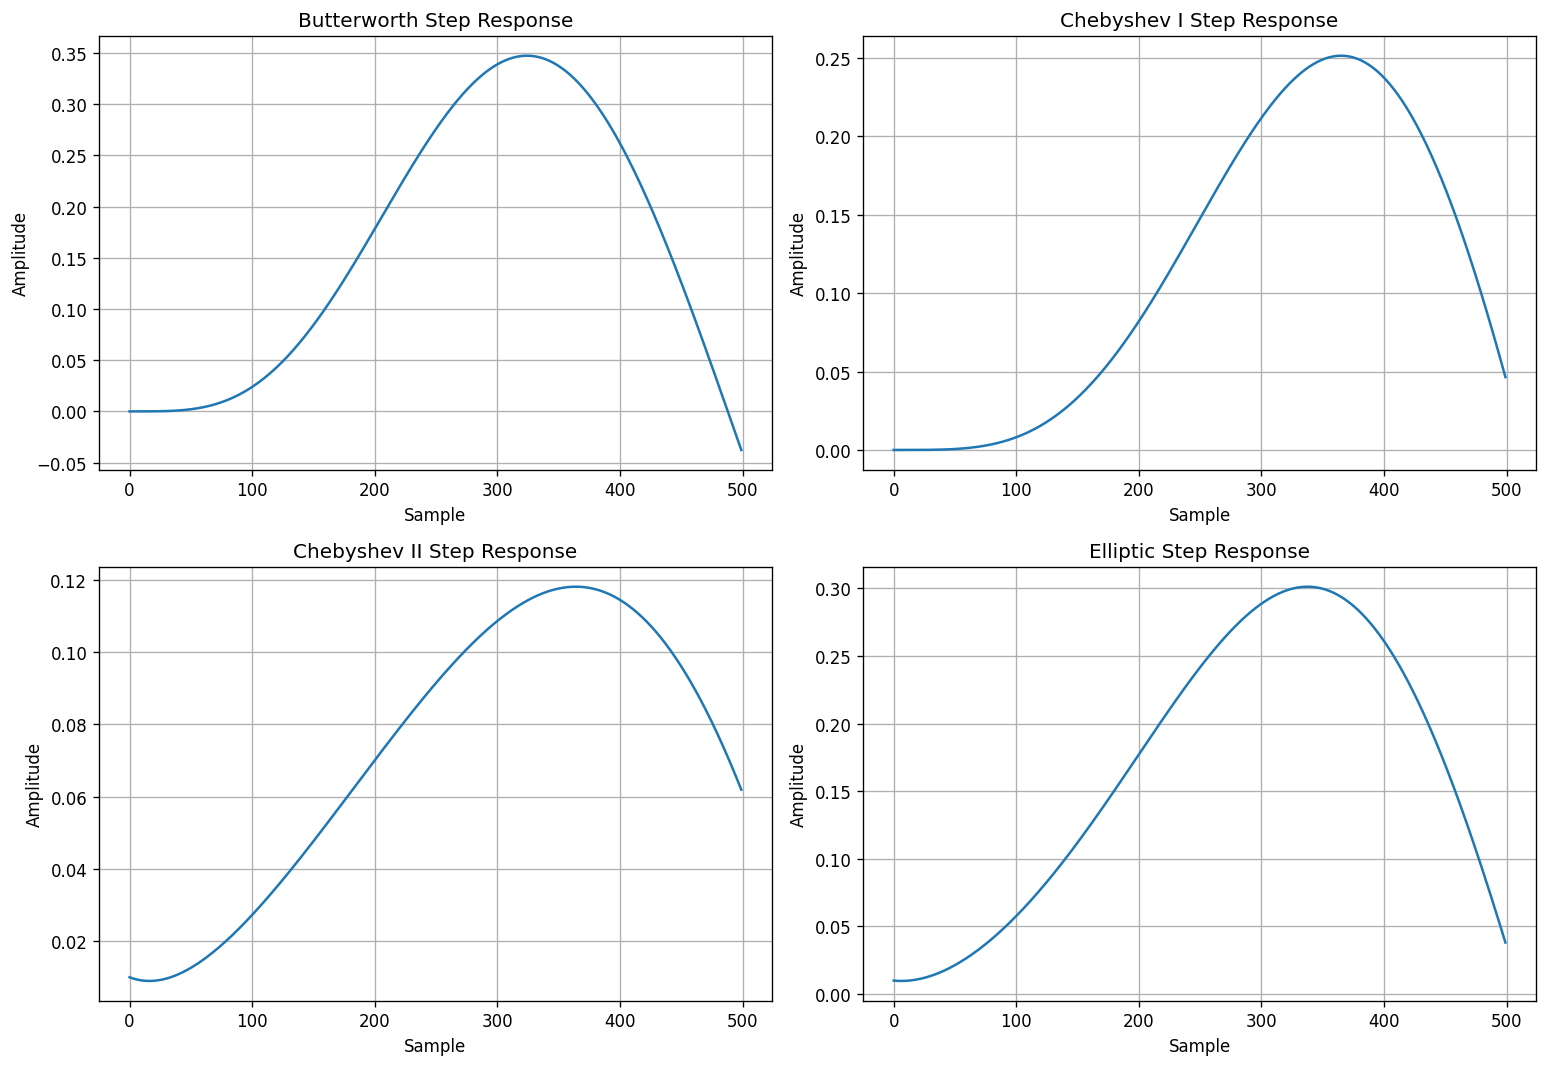

In [27]:

# Generate step input

step_input = np.ones(N_impulse)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, (name, sos) in zip(axes.flatten(), iir_filters.items()):

    response = signal.sosfilt(sos, step_input)

    ax.plot(np.arange(N_impulse), response)

    ax.set_title(f"{name} Step Response")
    ax.set_xlabel("Sample")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

plt.tight_layout()

plt.savefig("../figures/15_iir_step_response.png")
plt.show()


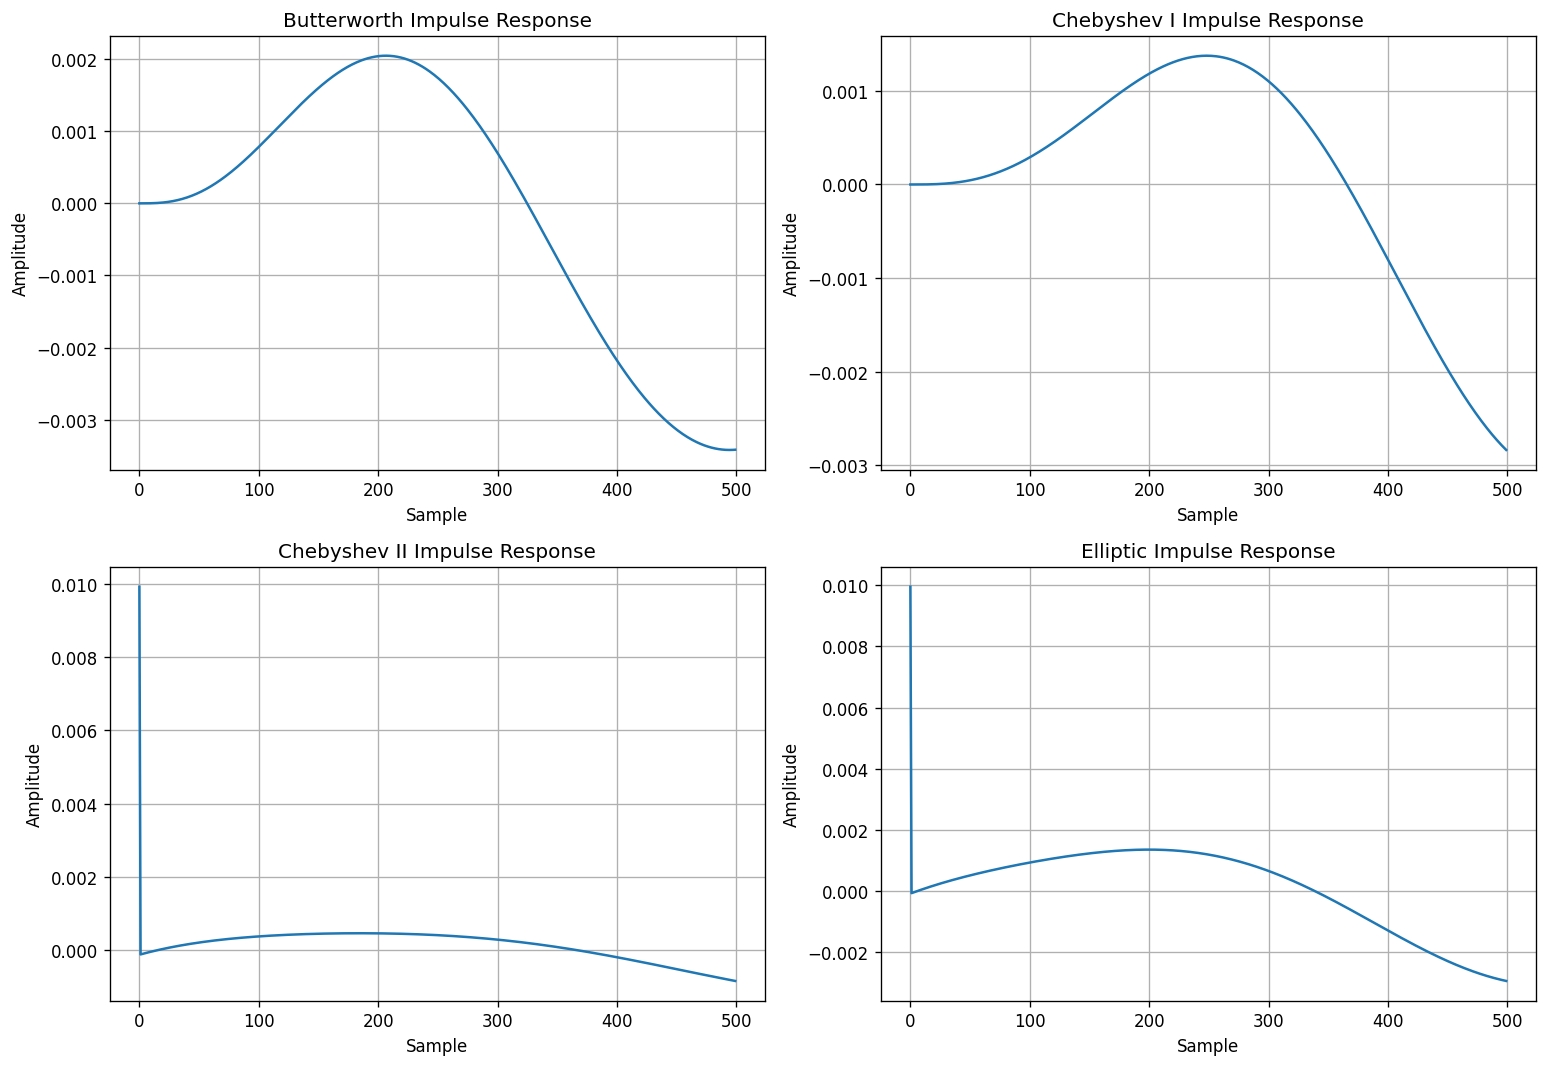

In [26]:

# Generate impulse input

N_impulse = 500

impulse = np.zeros(N_impulse)
impulse[0] = 1

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, (name, sos) in zip(axes.flatten(), iir_filters.items()):

    response = signal.sosfilt(sos, impulse)

    ax.plot(np.arange(N_impulse), response)

    ax.set_title(f"{name} Impulse Response")
    ax.set_xlabel("Sample")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

plt.tight_layout()

plt.savefig("../figures/14_iir_impulse_response.png")
plt.show()


In [25]:

# IIR stability analysis

stability_results = []

for name, sos in iir_filters.items():

    zeros, poles, gain = signal.sos2zpk(sos)

    max_pole = np.max(np.abs(poles))

    stability_results.append({
        "Filter": name,
        "Maximum Pole Magnitude": max_pole,
        "Stable": max_pole < 1
    })

stability_df = pd.DataFrame(stability_results)

display(stability_df.round(6))


,Filter,Maximum Pole Magnitude,Stable
0,Butterworth,0.999327,True
1,Chebyshev I,0.999763,True
2,Chebyshev II,0.999480,True
3,Elliptic,0.999823,True


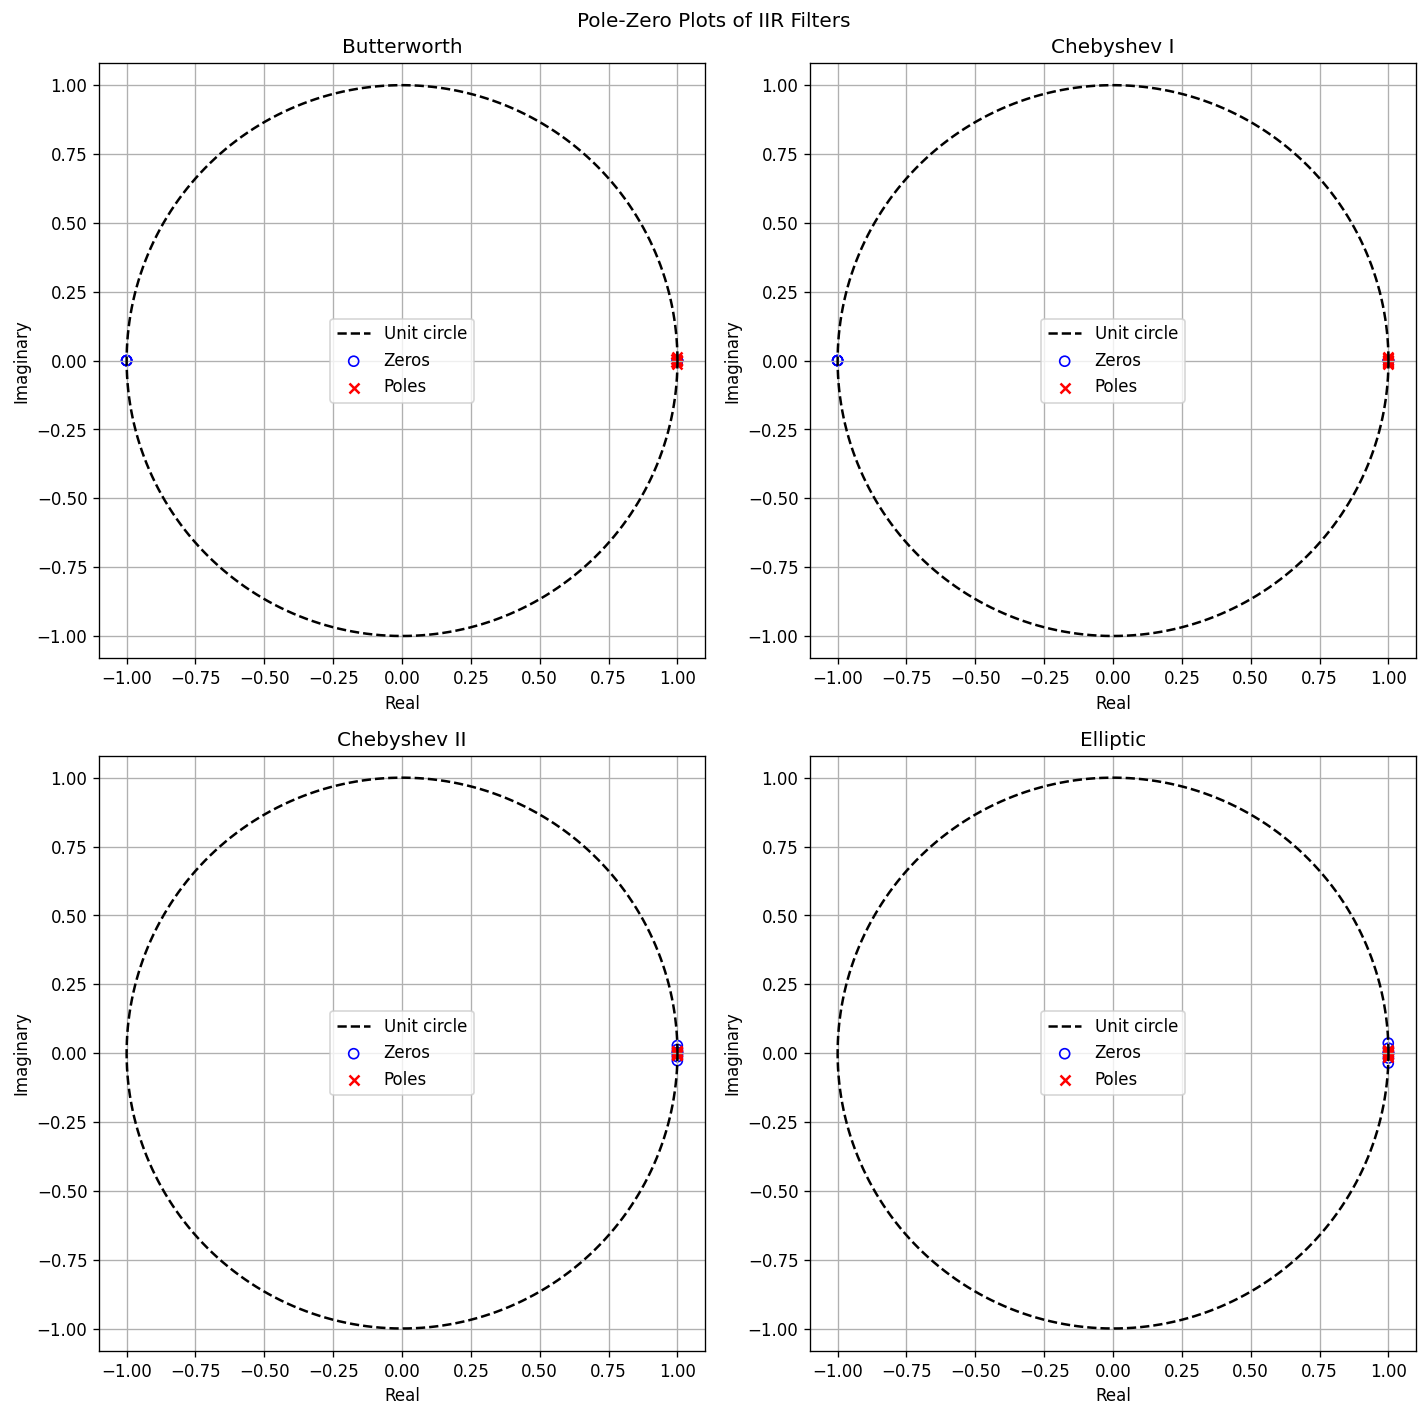

In [24]:

# Convert IIR filters from SOS to zero-pole-gain format

iir_filters = {
    "Butterworth": resp_sos,
    "Chebyshev I": resp_cheby1,
    "Chebyshev II": resp_cheby2,
    "Elliptic": resp_ellip
}

fig, axes = plt.subplots(2, 2, figsize=(12, 12))

for ax, (name, sos) in zip(axes.flatten(), iir_filters.items()):

    zeros, poles, gain = signal.sos2zpk(sos)

    # Unit circle
    theta = np.linspace(0, 2*np.pi, 500)

    ax.plot(np.cos(theta), np.sin(theta), "k--",
            label="Unit circle")

    # Zeros
    ax.scatter(
        np.real(zeros),
        np.imag(zeros),
        marker="o",
        facecolors="none",
        edgecolors="blue",
        label="Zeros"
    )

    # Poles
    ax.scatter(
        np.real(poles),
        np.imag(poles),
        marker="x",
        color="red",
        label="Poles"
    )

    ax.set_title(name)
    ax.set_xlabel("Real")
    ax.set_ylabel("Imaginary")
    ax.grid(True)
    ax.axis("equal")
    ax.legend()

plt.suptitle("Pole-Zero Plots of IIR Filters")
plt.tight_layout()

plt.savefig("../figures/13_pole_zero_iir.png")
plt.show()


In [23]:

filter_results = []

filter_bank = [
    ("Butterworth", resp_sos, fs, "sos"),
    ("Chebyshev I", resp_cheby1, fs, "sos"),
    ("Chebyshev II", resp_cheby2, fs, "sos"),
    ("Elliptic", resp_ellip, fs, "sos"),
    ("Kaiser FIR 250 Hz", resp_fir_kaiser, fs, "fir"),
    ("Kaiser FIR 25 Hz", resp_fir_25, fs_decimated, "fir"),
    ("Parks-McClellan", resp_fir_remez, fs_decimated, "fir"),
    ("Butterworth 25 Hz", resp_sos_25, fs_decimated, "sos")
]

for name, coefficients, sampling_rate, kind in filter_bank:

    ripple, attenuation = measure_filter_performance(
        coefficients,
        sampling_rate,
        kind
    )

    filter_results.append({
        "Filter": name,
        "Passband Ripple (dB)": ripple,
        "Stopband Attenuation (dB)": attenuation
    })

performance_df = pd.DataFrame(filter_results)

display(performance_df.round(3))


,Filter,Passband Ripple (dB),Stopband Attenuation (dB)
0,Butterworth,2.996,15.932
1,Chebyshev I,0.999,23.851
2,Chebyshev II,39.886,40.000
3,Elliptic,0.999,40.000
4,Kaiser FIR 250 Hz,5.983,45.299
5,Kaiser FIR 25 Hz,5.986,45.092
6,Parks-McClellan,0.408,52.582
7,Butterworth 25 Hz,2.996,15.888


In [22]:
print("Checking filter availability:")

for name in [
    "resp_sos",
    "resp_cheby1",
    "resp_cheby2",
    "resp_ellip",
    "resp_fir_kaiser",
    "resp_fir_25",
    "resp_fir_remez",
    "resp_sos_25"
]:
    print(name, ":", "Available" if name in globals() else "Missing")

Checking filter availability:
resp_sos : Available
resp_cheby1 : Available
resp_cheby2 : Available
resp_ellip : Available
resp_fir_kaiser : Available
resp_fir_25 : Available
resp_fir_remez : Available
resp_sos_25 : Available


In [21]:

# Parks-McClellan FIR filter design

bands = [
    0, 0.05,
    0.1, 0.5,
    0.7, fs_decimated / 2
]

desired = [0, 1, 0]
weights = [10, 1, 10]

remez_taps = 1001

resp_fir_remez = signal.remez(
    remez_taps,
    bands,
    desired,
    weight=weights,
    fs=fs_decimated,
    maxiter=100,
    grid_density=32
)

print("Parks-McClellan filter created!")
print("Number of taps:", len(resp_fir_remez))


Parks-McClellan filter created!
Number of taps: 1001


In [20]:

filter_results = []

filter_bank = [
    ("Butterworth", resp_sos, fs, "sos"),
    ("Chebyshev I", resp_cheby1, fs, "sos"),
    ("Chebyshev II", resp_cheby2, fs, "sos"),
    ("Elliptic", resp_ellip, fs, "sos"),
    ("Kaiser FIR 250 Hz", resp_fir_kaiser, fs, "fir"),
    ("Kaiser FIR 25 Hz", resp_fir_25, fs_decimated, "fir"),
    ("Parks-McClellan", resp_fir_remez, fs_decimated, "fir"),
    ("Butterworth 25 Hz", resp_sos_25, fs_decimated, "sos")
]

for name, coefficients, sampling_rate, kind in filter_bank:

    ripple, attenuation = measure_filter_performance(
        coefficients,
        sampling_rate,
        kind
    )

    filter_results.append({
        "Filter": name,
        "Passband Ripple (dB)": ripple,
        "Stopband Attenuation (dB)": attenuation
    })

performance_df = pd.DataFrame(filter_results)

display(performance_df.round(3))


NameError: name 'resp_fir_remez' is not defined

In [19]:

def measure_filter_performance(filter_data, fs, filter_type="sos"):

    if filter_type == "sos":
        freq, response = signal.sosfreqz(
            filter_data,
            worN=32768,
            fs=fs
        )
    else:
        freq, response = signal.freqz(
            filter_data,
            worN=32768,
            fs=fs
        )

    magnitude_db = 20 * np.log10(
        np.maximum(np.abs(response), 1e-15)
    )

    # Define frequency regions
    passband = (freq >= 0.1) & (freq <= 0.5)

    low_stopband = freq <= 0.05
    high_stopband = freq >= 0.7

    stopband = low_stopband | high_stopband

    # Calculate performance
    passband_ripple = (
        np.max(magnitude_db[passband]) -
        np.min(magnitude_db[passband])
    )

    stopband_attenuation = -np.max(
        magnitude_db[stopband]
    )

    return passband_ripple, stopband_attenuation


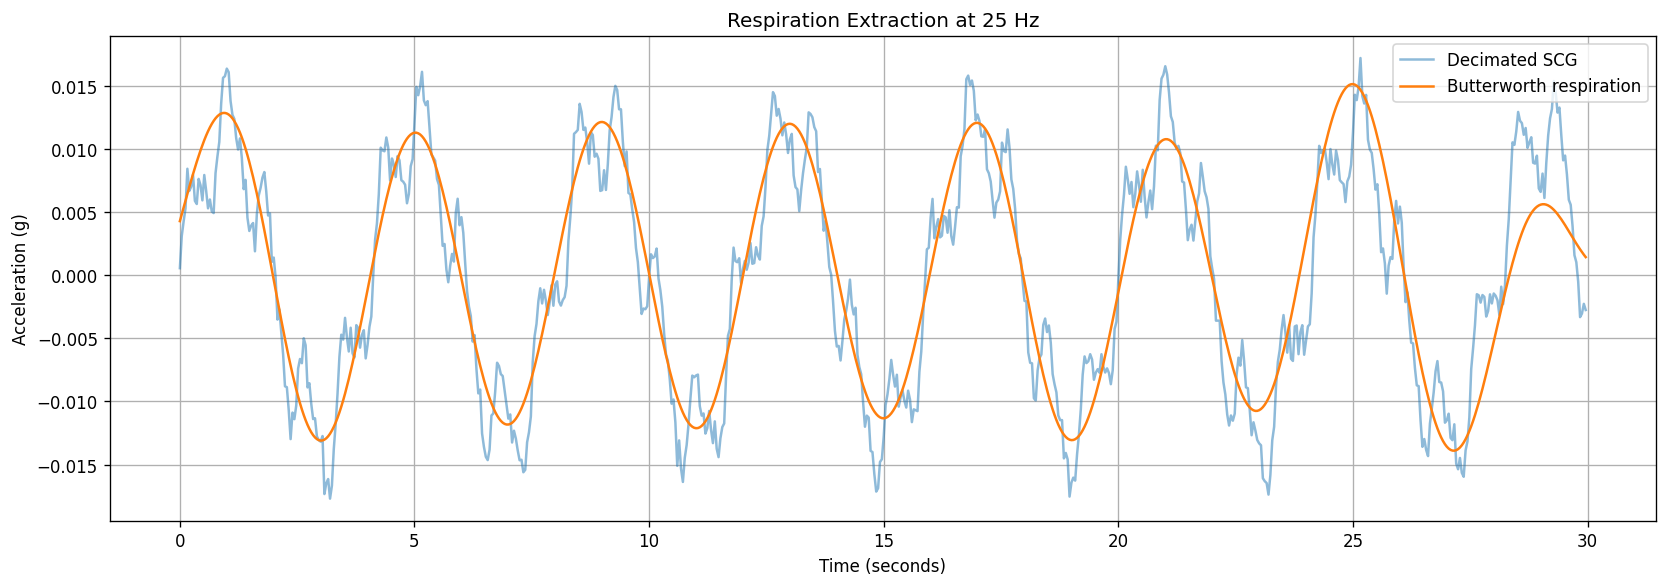

In [18]:

# Apply Butterworth respiration filter at 25 Hz

resp_sos_25 = signal.butter(
    N=4,
    Wn=[0.1, 0.5],
    btype="bandpass",
    fs=fs_decimated,
    output="sos"
)

resp_iir_25 = signal.sosfiltfilt(
    resp_sos_25,
    x_decimated
)

# Plot filtered output

plt.figure(figsize=(14, 5))

plt.plot(time_decimated, x_decimated,
         alpha=0.5, label="Decimated SCG")

plt.plot(time_decimated, resp_iir_25,
         label="Butterworth respiration")

plt.xlabel("Time (seconds)")
plt.ylabel("Acceleration (g)")
plt.title("Respiration Extraction at 25 Hz")

plt.legend()
plt.tight_layout()
plt.show()


In [17]:
print("FIR FILTER LENGTH ANALYSIS")

print("FIR taps:", len(resp_fir_25))
print("Available samples:", len(x_decimated))

required_padlen = 3 * (len(resp_fir_25) - 1)

print("Required padding:", required_padlen)
print("Available samples:", len(x_decimated))

if len(x_decimated) <= required_padlen:
    print("\nRecording too short for filtfilt.")
else:
    print("\nRecording is long enough for filtfilt.")

FIR FILTER LENGTH ANALYSIS
FIR taps: 1119
Available samples: 750
Required padding: 3354
Available samples: 750

Recording too short for filtfilt.


In [16]:

# Apply zero-phase FIR filtering at 25 Hz

resp_fir_output = signal.filtfilt(
    resp_fir_25,
    [1.0],
    x_decimated
)

plt.figure(figsize=(14, 5))

plt.plot(
    time_decimated,
    x_decimated,
    alpha=0.5,
    label="Decimated SCG"
)

plt.plot(
    time_decimated,
    resp_fir_output,
    label="Kaiser FIR respiration"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Acceleration (g)")
plt.title("Respiration Extraction Using Kaiser FIR at 25 Hz")

plt.legend()
plt.tight_layout()

plt.savefig("../figures/08_kaiser_fir.png")
plt.show()


ValueError: The length of the input vector x must be greater than padlen, which is 3357.

In [15]:

# Design Kaiser FIR at the reduced sampling frequency

attenuation = 40
transition_width = 0.05

numtaps_25, beta_25 = signal.kaiserord(
    attenuation,
    transition_width / (fs_decimated / 2)
)

if numtaps_25 % 2 == 0:
    numtaps_25 += 1

resp_fir_25 = signal.firwin(
    numtaps_25,
    [0.1, 0.5],
    pass_zero=False,
    window=("kaiser", beta_25),
    fs=fs_decimated
)

print("Number of FIR taps:", numtaps_25)
print("Filter order:", numtaps_25 - 1)


Number of FIR taps: 1119
Filter order: 1118


In [14]:

# Decimate the original signal from 250 Hz to 25 Hz

DECIMATION_FACTOR = 10

x_decimated = signal.resample_poly(
    x,
    up=1,
    down=DECIMATION_FACTOR
)

fs_decimated = fs / DECIMATION_FACTOR

time_decimated = np.arange(len(x_decimated)) / fs_decimated

print("Original samples:", len(x))
print("Decimated samples:", len(x_decimated))
print("New sampling frequency:", fs_decimated)


Original samples: 7500
Decimated samples: 750
New sampling frequency: 24.99999999999998


In [12]:

# FIR design specifications

resp_low = 0.1
resp_high = 0.5

# Transition width in Hz
transition_width = 0.05

# Kaiser window design
numtaps, beta = signal.kaiserord(
    40,  # Desired attenuation in dB
    transition_width / (fs / 2)
)

# Ensure odd number of taps for a Type-I linear-phase FIR
if numtaps % 2 == 0:
    numtaps += 1

resp_fir_kaiser = signal.firwin(
    numtaps,
    [resp_low, resp_high],
    pass_zero=False,
    window=("kaiser", beta),
    fs=fs
)

print("Kaiser FIR designed")
print("Number of taps:", numtaps)
print("Filter order:", numtaps - 1)
print("Kaiser beta:", beta)


Kaiser FIR designed
Number of taps: 11163
Filter order: 11162
Kaiser beta: 3.3953210522614574


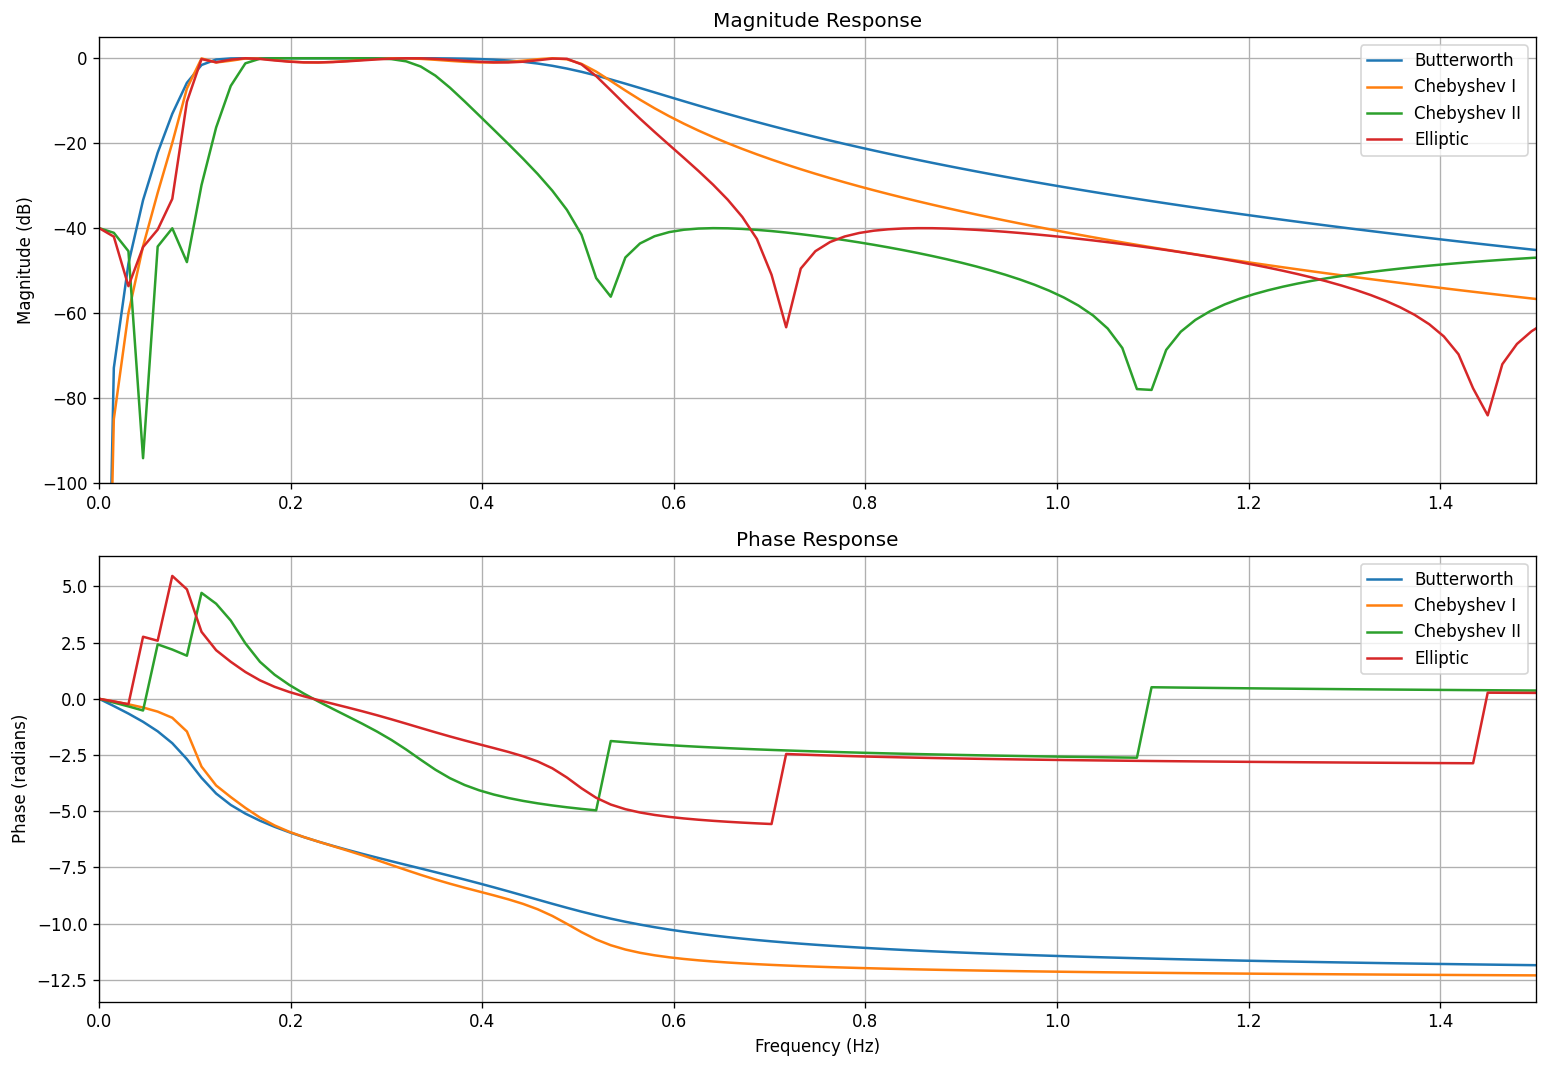

In [11]:

fig, axes = plt.subplots(2, 1, figsize=(13, 9))

for name, sos in filters.items():

    freq, response = signal.sosfreqz(
        sos,
        worN=8192,
        fs=fs
    )

    magnitude_db = 20 * np.log10(
        np.maximum(np.abs(response), 1e-12)
    )

    phase = np.unwrap(np.angle(response))

    axes[0].plot(freq, magnitude_db, label=name)
    axes[1].plot(freq, phase, label=name)

axes[0].set_xlim(0, 1.5)
axes[0].set_ylim(-100, 5)
axes[0].set_title("Magnitude Response")
axes[0].set_ylabel("Magnitude (dB)")

axes[1].set_xlim(0, 1.5)
axes[1].set_title("Phase Response")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Phase (radians)")

axes[0].legend()
axes[1].legend()

plt.tight_layout()
plt.savefig("../figures/07_magnitude_phase.png")
plt.show()


In [10]:

print("IIR Filter Complexity Comparison\n")

for name, sos in filters.items():

    sections = sos.shape[0]
    total_order = 2 * sections

    print(f"{name}")
    print(f"  Second-order sections: {sections}")
    print(f"  Overall order: {total_order}")
    print(f"  Coefficients: {sos.size}")
    print()


IIR Filter Complexity Comparison

Butterworth
  Second-order sections: 4
  Overall order: 8
  Coefficients: 24

Chebyshev I
  Second-order sections: 4
  Overall order: 8
  Coefficients: 24

Chebyshev II
  Second-order sections: 4
  Overall order: 8
  Coefficients: 24

Elliptic
  Second-order sections: 4
  Overall order: 8
  Coefficients: 24



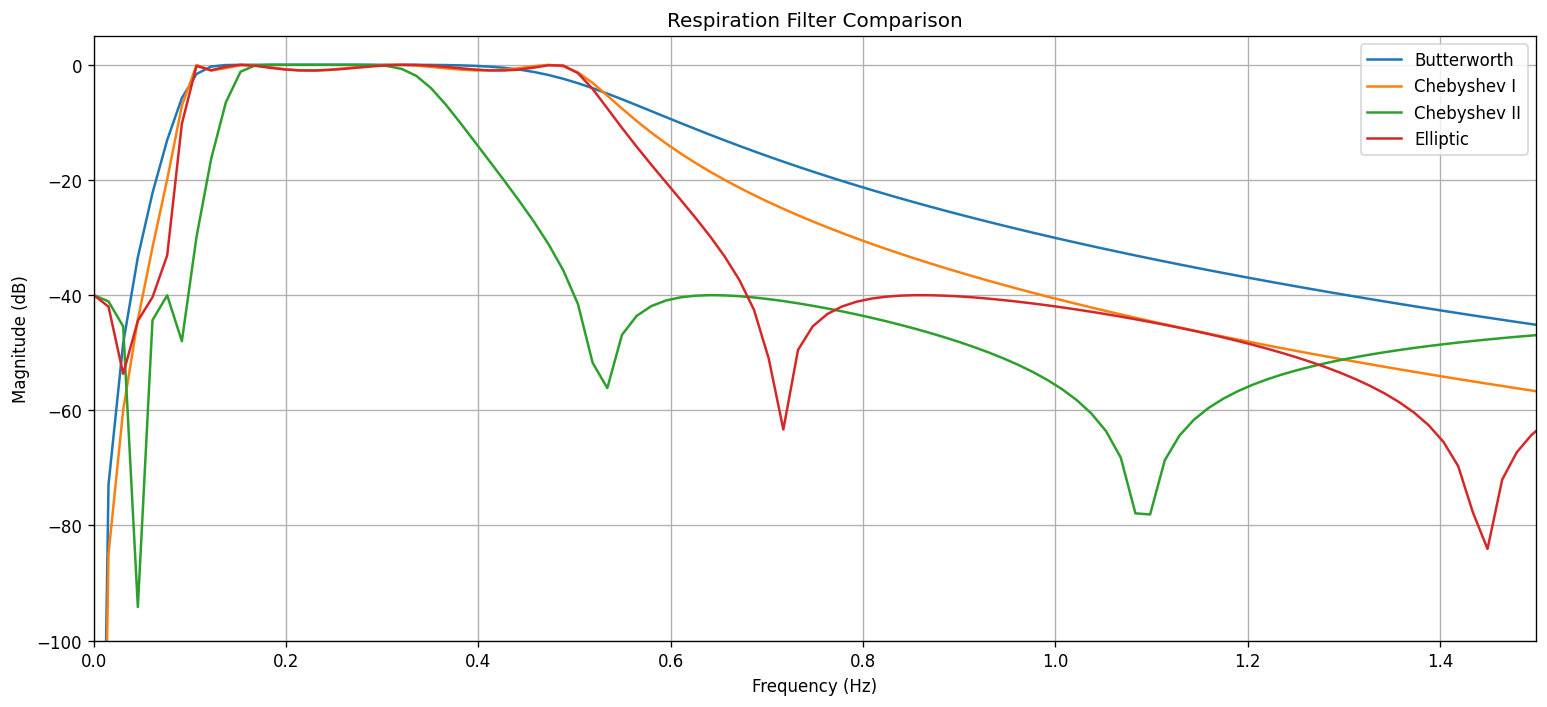

In [9]:

filters = {
    "Butterworth": resp_sos,
    "Chebyshev I": resp_cheby1,
    "Chebyshev II": resp_cheby2,
    "Elliptic": resp_ellip
}

plt.figure(figsize=(13, 6))

for name, sos in filters.items():

    freq, response = signal.sosfreqz(
        sos,
        worN=8192,
        fs=fs
    )

    magnitude_db = 20 * np.log10(
        np.maximum(np.abs(response), 1e-12)
    )

    plt.plot(freq, magnitude_db, label=name)

plt.xlim(0, 1.5)
plt.ylim(-100, 5)

plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.title("Respiration Filter Comparison")

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig("../figures/06_iir_filter_comparison.png")
plt.show()


In [8]:

# Elliptic filters

resp_ellip = signal.ellip(
    N=4,
    rp=1,
    rs=40,
    Wn=[0.1, 0.5],
    btype="bandpass",
    fs=fs,
    output="sos"
)

heart_ellip = signal.ellip(
    N=4,
    rp=1,
    rs=40,
    Wn=[0.8, 20],
    btype="bandpass",
    fs=fs,
    output="sos"
)

# Apply filters
resp_ellip_out = signal.sosfiltfilt(resp_ellip, x)
heart_ellip_out = signal.sosfiltfilt(heart_ellip, x)

print("Elliptic filters designed and applied.")


Elliptic filters designed and applied.


In [7]:

# Chebyshev Type II filters

resp_cheby2 = signal.cheby2(
    N=4,
    rs=40,
    Wn=[0.1, 0.5],
    btype="bandpass",
    fs=fs,
    output="sos"
)

heart_cheby2 = signal.cheby2(
    N=4,
    rs=40,
    Wn=[0.8, 20],
    btype="bandpass",
    fs=fs,
    output="sos"
)

# Apply filters
resp_cheby2_out = signal.sosfiltfilt(resp_cheby2, x)
heart_cheby2_out = signal.sosfiltfilt(heart_cheby2, x)

print("Chebyshev Type II filters designed and applied.")


Chebyshev Type II filters designed and applied.


In [6]:

# Chebyshev Type I filters

resp_cheby1 = signal.cheby1(
    N=4,
    rp=1,
    Wn=[0.1, 0.5],
    btype="bandpass",
    fs=fs,
    output="sos"
)

heart_cheby1 = signal.cheby1(
    N=4,
    rp=1,
    Wn=[0.8, 20],
    btype="bandpass",
    fs=fs,
    output="sos"
)

# Apply filters
resp_cheby1_out = signal.sosfiltfilt(resp_cheby1, x)
heart_cheby1_out = signal.sosfiltfilt(heart_cheby1, x)

print("Chebyshev Type I filters designed and applied.")


Chebyshev Type I filters designed and applied.


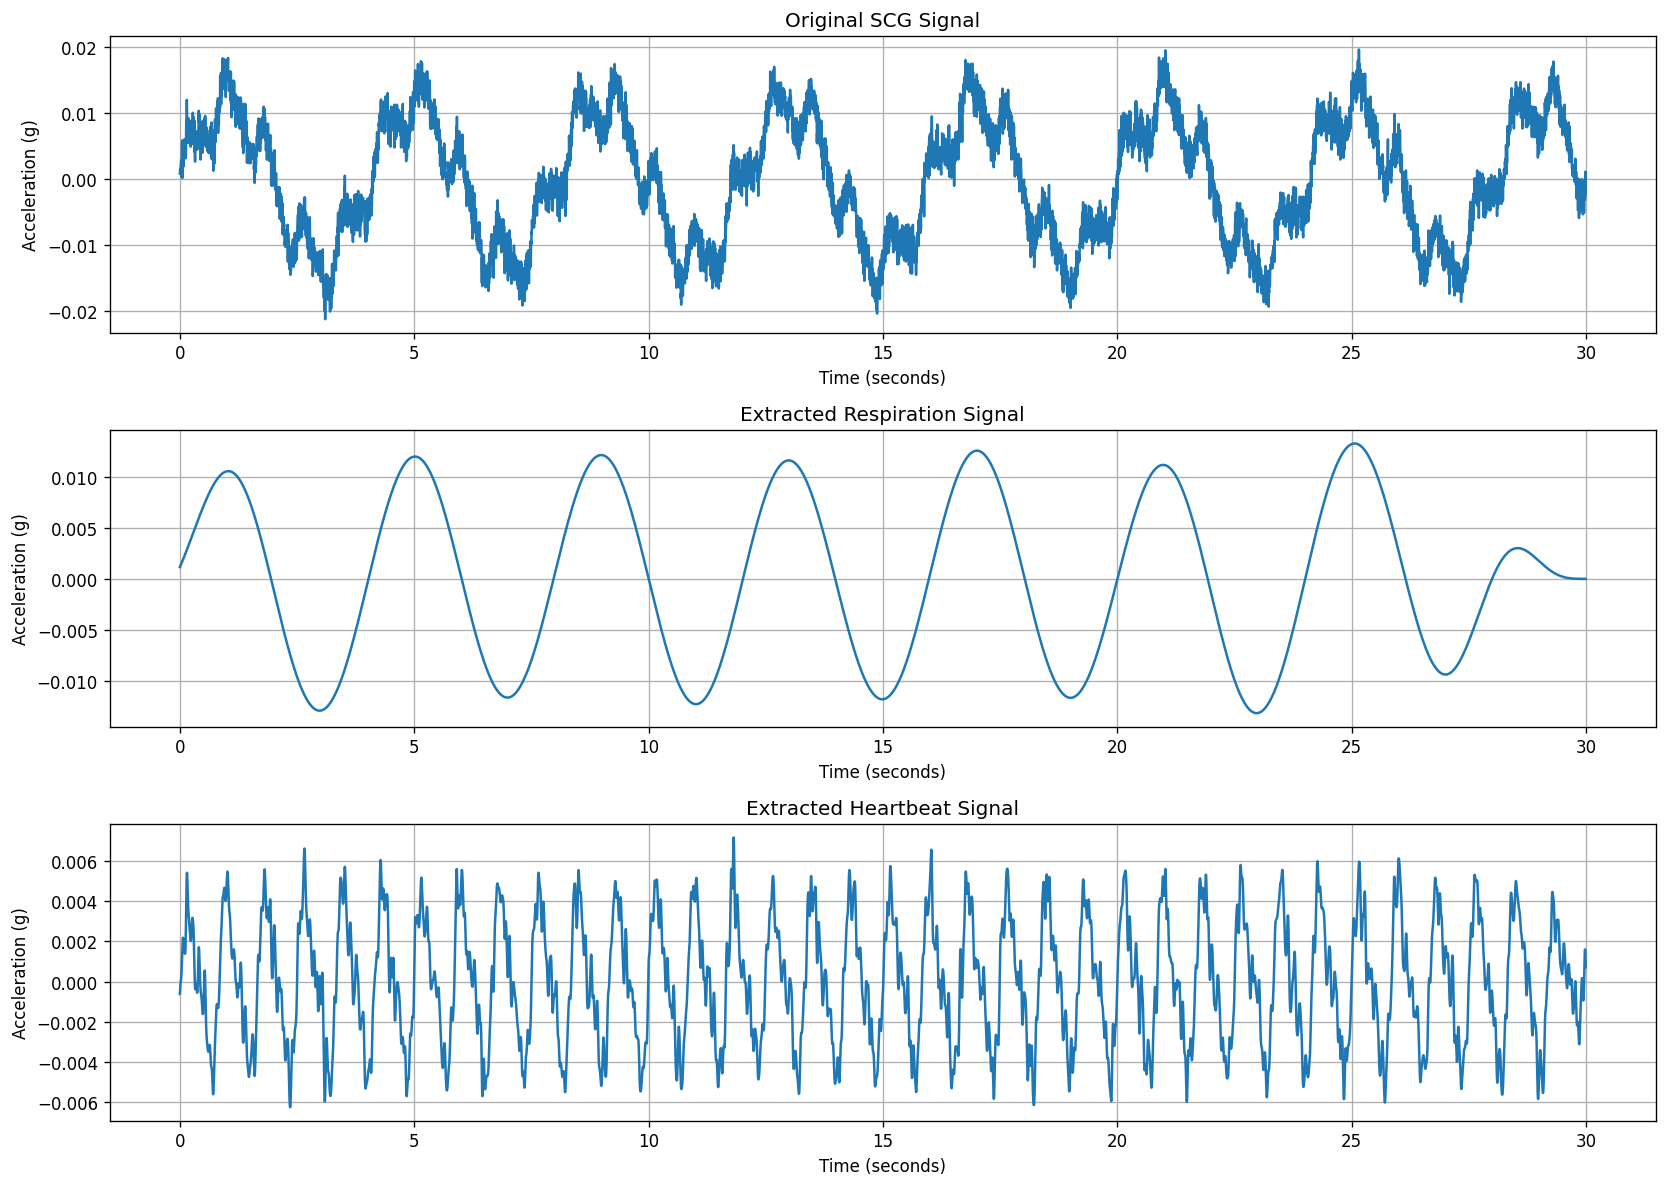

In [5]:

# Offline zero-phase filtering

resp_signal = signal.sosfiltfilt(resp_sos, x)

heart_signal = signal.sosfiltfilt(heart_sos, x)

# Plot original and filtered signals

fig, axes = plt.subplots(3, 1, figsize=(14, 10))

axes[0].plot(time, x)
axes[0].set_title("Original SCG Signal")

axes[1].plot(time, resp_signal)
axes[1].set_title("Extracted Respiration Signal")

axes[2].plot(time, heart_signal)
axes[2].set_title("Extracted Heartbeat Signal")

for ax in axes:
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Acceleration (g)")

plt.tight_layout()
plt.savefig("../figures/05_butterworth_output.png")
plt.show()


In [4]:

# Design Butterworth filters

resp_sos = signal.butter(
    N=4,
    Wn=FILTER_SPECS["respiration"]["passband"],
    btype="bandpass",
    fs=fs,
    output="sos"
)

heart_sos = signal.butter(
    N=4,
    Wn=FILTER_SPECS["heartbeat"]["passband"],
    btype="bandpass",
    fs=fs,
    output="sos"
)

print("Butterworth filters designed successfully.")


Butterworth filters designed successfully.


In [3]:

# Filter specifications

FILTER_SPECS = {
    "respiration": {
        "passband": [0.1, 0.5],
        "stopband": [0.05, 0.7],
        "rp": 1,
        "rs": 40
    },

    "heartbeat": {
        "passband": [0.8, 20],
        "stopband": [0.5, 25],
        "rp": 1,
        "rs": 40
    }
}

print("Filter specifications defined.")


Filter specifications defined.


In [2]:

# Load processed SCG data

DATA_PATH = Path("../data/processed/scg_processed.csv")

df = pd.read_csv(DATA_PATH)

time = df["timestamp_ms"].to_numpy() / 1000

fs = 1 / np.median(np.diff(time))

# Select Z-axis signal
x = df["az_g_clean"].to_numpy()

print("Data loaded successfully")
print(f"Sampling frequency: {fs:.2f} Hz")
print(f"Number of samples: {len(x)}")


Data loaded successfully
Sampling frequency: 250.00 Hz
Number of samples: 7500


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import signal
from pathlib import Path

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.grid"] = True

print("Filter design environment ready!")


Filter design environment ready!
